# Visualize fixed-effects model results

Load saved `change_did` outputs and create figures; this notebook does not
recompute statistics. Results cover two model specifications — **site +
period** and **period-only** — and every model-dependent figure is drawn once
per model, saved under each index's `plots/<model>/` folder. Placebo figures
compare the real event estimate with the placebo distributions, and the
sensitivity forest shows the event estimate across τ thresholds and missing-SE
policies. Figures for every configured index are saved; only `PLOT_INDEX` is
displayed inline. For the method, see the
[site + period methods](../docs/white-papers/Before-After-Control-Impact-Analysis.md)
and [period-only methods](../docs/white-papers/Period-Only-Control-Impact-Analysis.md).


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from change_did import MODEL_LABELS, DidAnalysisConfig
from change_did.plotting import (
    plot_anomaly_heatmap,
    plot_change_trajectories,
    plot_combined_evidence,
    plot_combined_evidence_by_index,
    plot_observed_vs_counterfactual,
    plot_placebo_space,
    plot_placebo_spacetime,
    plot_sensitivity_forest,
    save_figure,
)
from index_ci.config import IndexAnalysisConfig
from index_ci.plotting import plot_index_timeseries
from plot_style import add_shared_legend, month_name, site_order

ROOT = Path.cwd().parent
assert (ROOT / "pyproject.toml").exists(), "Run notebooks from the notebooks/ folder"
CONFIG = DidAnalysisConfig.from_yaml(
    ROOT / "configs" / "change_did.yaml", project_root=ROOT
)
MODELS = CONFIG.models

## Load saved outputs

In [2]:
PLOT_INDEX = "NDVI"
if PLOT_INDEX not in CONFIG.indices:
    raise ValueError(f"Index is not configured: {PLOT_INDEX}")

def load_outputs(index, model=None):
    results_dir = CONFIG.output_dir / index
    frames = (
        pd.read_csv(results_dir / "did_main.csv"),
        pd.read_csv(results_dir / "did_placebo_space.csv"),
        pd.read_csv(results_dir / "did_placebo_spacetime.csv"),
        pd.read_csv(results_dir / "did_anomalies.csv"),
    )
    if model is None:
        return frames
    return tuple(
        frame.loc[frame["model"] == model].reset_index(drop=True)
        for frame in frames
    )

main, placebo_space, placebo_spacetime, anomalies = load_outputs(PLOT_INDEX)
print(
    f"{len(main)} main rows, {len(placebo_space)} placebo-space rows, "
    f"{len(placebo_spacetime)} placebo-space-and-time rows, "
    f"{len(anomalies)} anomaly rows for {PLOT_INDEX} "
    f"across models {list(MODELS)}"
)

76 main rows, 56 placebo-space rows, 280 placebo-space-and-time rows, 336 anomaly rows for NDVI across models ['site_period', 'period_only']


## Placebo-in-space

Each panel ranks the fake-affected-site estimates for one month against the
real estimate, per model. The title carries the month's one-sided p-value
(minimum 1/7) and the ratio of the real estimate to the largest absolute
placebo.


Site + period model


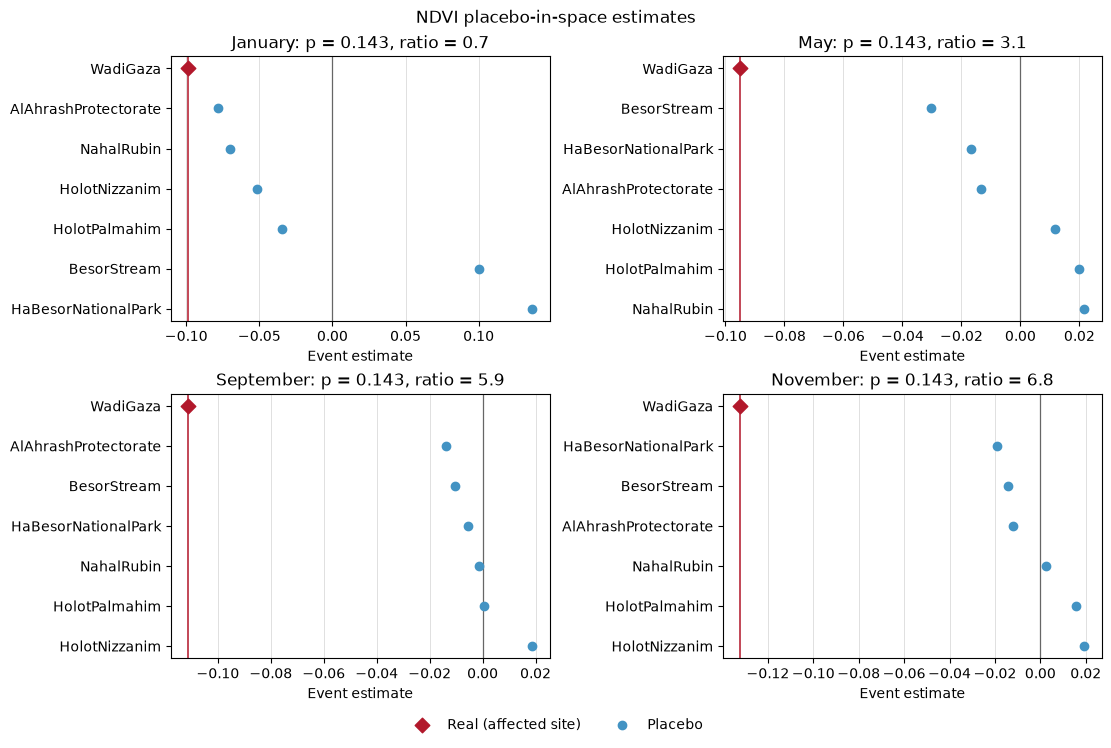

Period only model


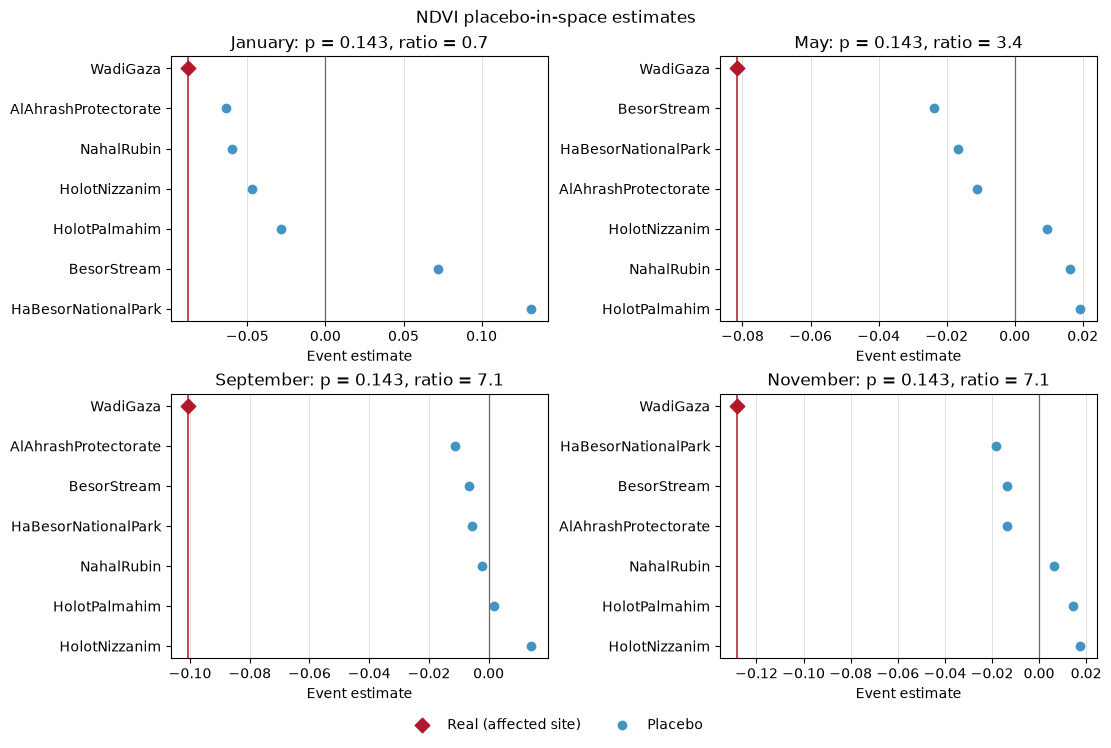

In [3]:
SHOW_INDICES = {PLOT_INDEX}  # indices displayed inline; figures for all are saved

for index in CONFIG.indices:
    for model in MODELS:
        _, index_space, _, _ = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_placebo_space(index_space)
        fig.suptitle(f"{index} placebo-in-space estimates")
        save_figure(fig, plot_dir / "placebo_space.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Placebo-in-space-and-time

Each panel ranks the 34 fake-event estimates (the second event pair is dropped
before fitting) against the real estimate, drawn as the highlighted vertical
line. The title carries the month's one-sided p-value (minimum 1/35).

Site + period model


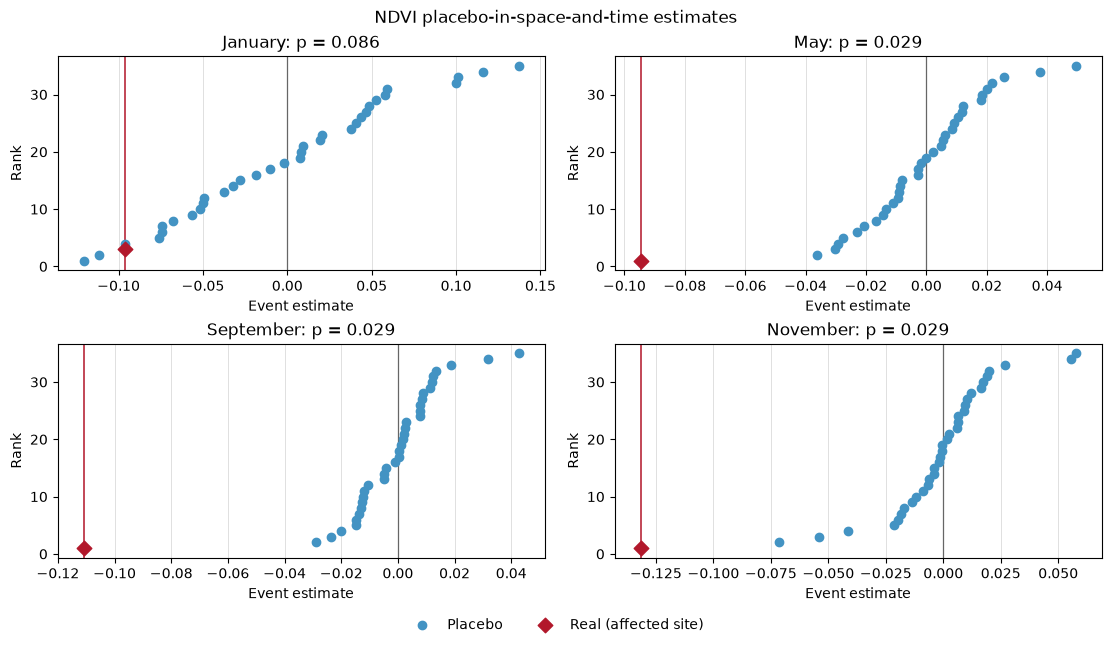

Period only model


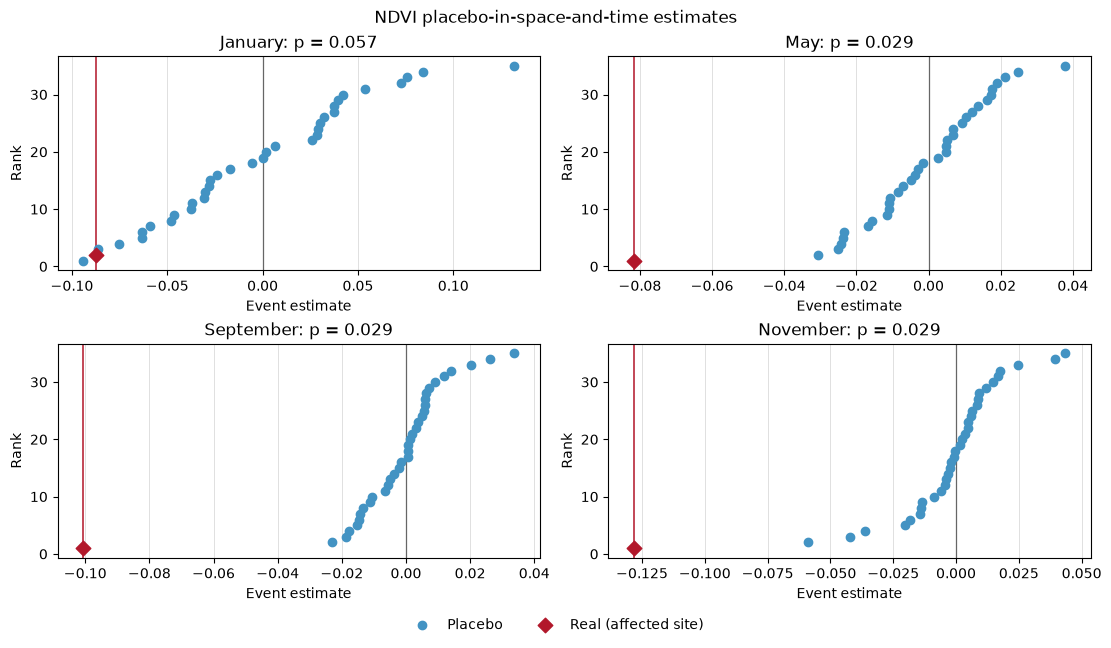

In [4]:
for index in CONFIG.indices:
    for model in MODELS:
        _, _, index_spacetime, _ = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_placebo_spacetime(index_spacetime)
        fig.suptitle(f"{index} placebo-in-space-and-time estimates")
        save_figure(fig, plot_dir / "placebo_spacetime.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Sensitivity of the event estimate

Each panel shows the event estimate and its 95% CI for one month across the
primary specification, the τ sensitivities, and both missing-SE policies, per
model.


Site + period model


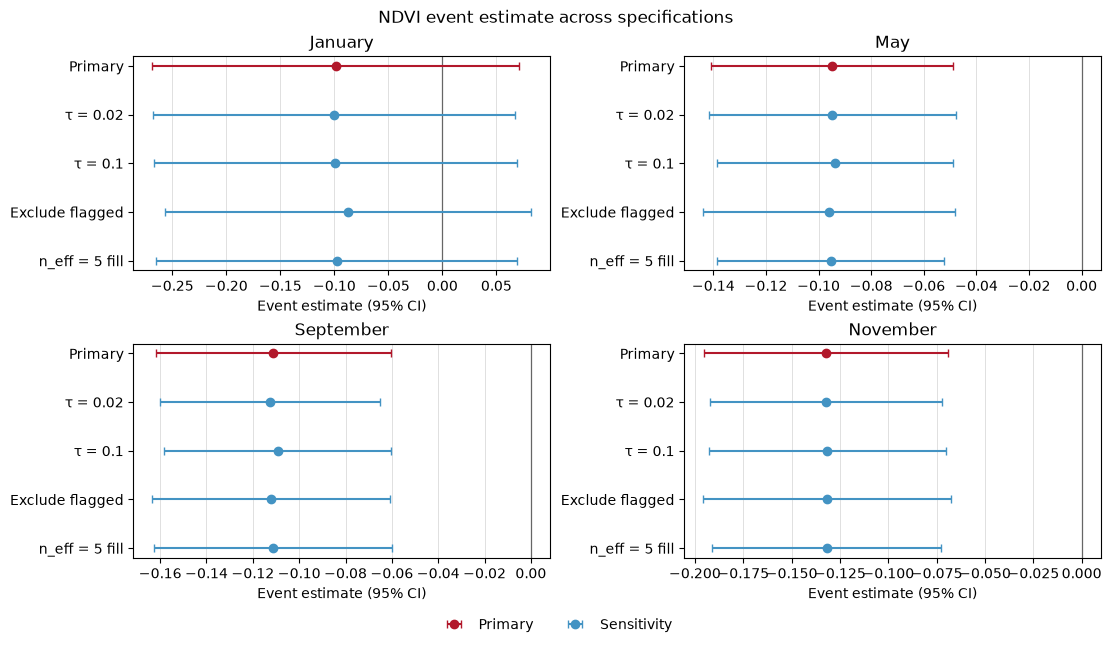

Period only model


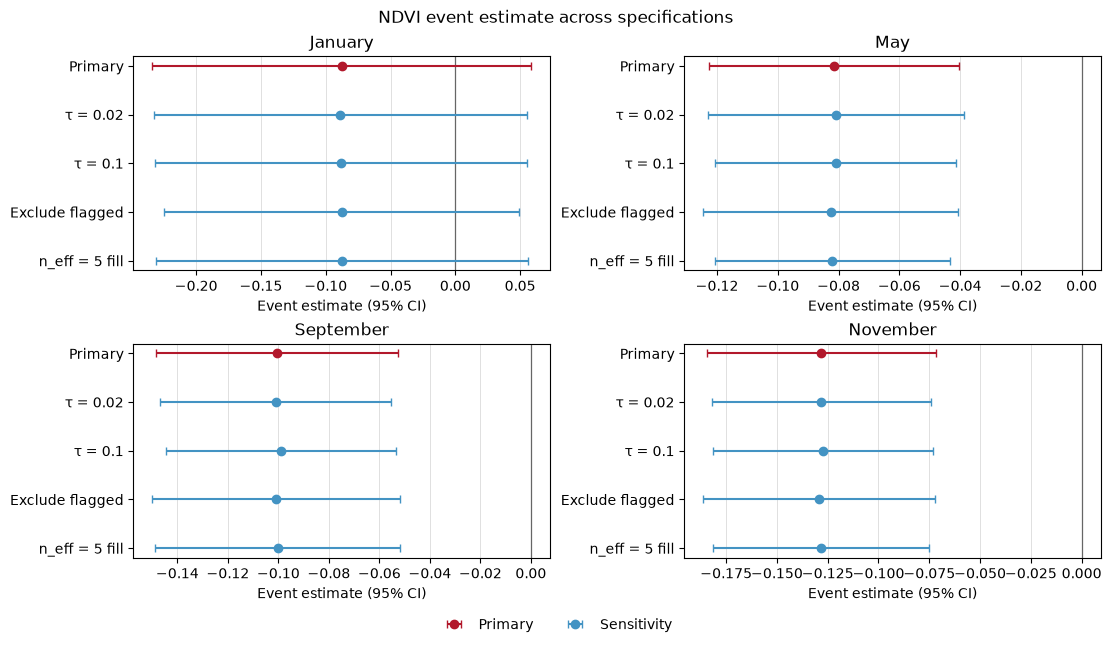

In [5]:
for index in CONFIG.indices:
    for model in MODELS:
        index_main, _, _, _ = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_sensitivity_forest(index_main)
        fig.suptitle(f"{index} event estimate across specifications")
        save_figure(fig, plot_dir / "sensitivity_forest.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Change trajectories in context

Each panel shows every site's mean change across consecutive year pairs for one
month: comparison sites in grey, the affected site highlighted with its
spatially adjusted 95% CI error bars (from the saved `change_ci` results), and the
event year pairs shaded. The story the model quantifies is visible directly: the
affected site moves with the pack until the event pairs.

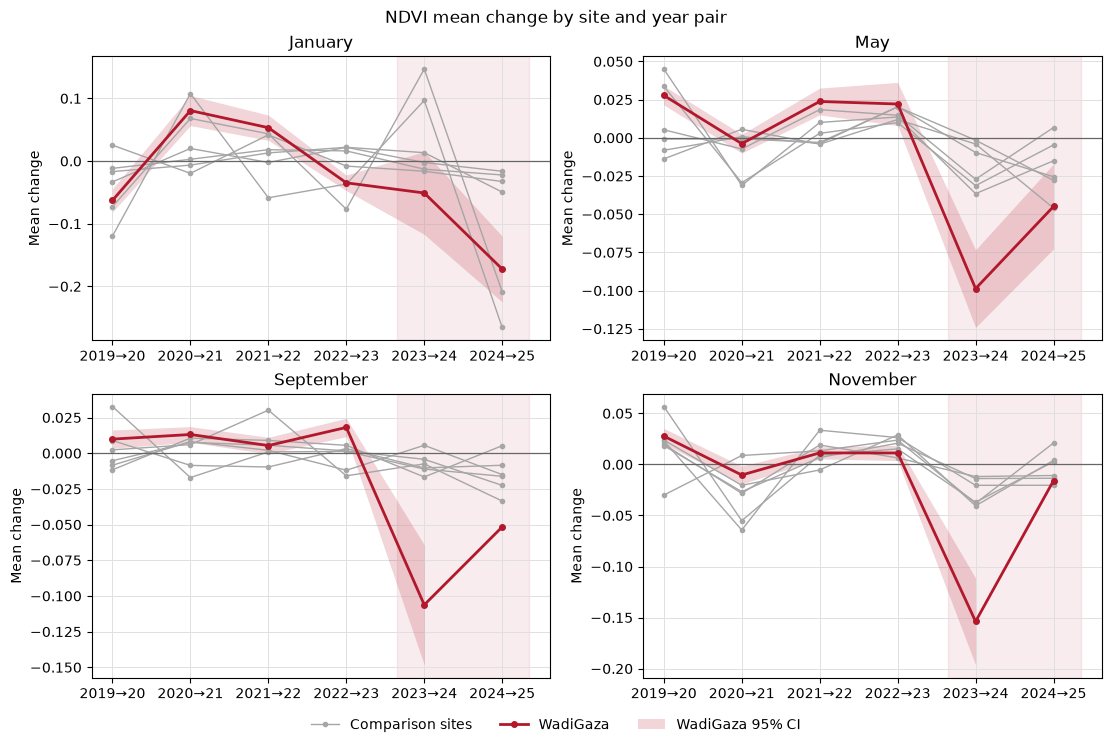

In [6]:
CHANGE_CI_DIR = ROOT / "outputs" / "change_ci"

for index in CONFIG.indices:
    change_results = pd.read_csv(CHANGE_CI_DIR / index / "results.csv")
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plot_change_trajectories(
        change_results, CONFIG.affected_site, CONFIG.event_pairs, months=CONFIG.months
    )
    fig.suptitle(f"{index} mean change by site and year pair")
    save_figure(fig, plot_dir / "change_trajectories.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Deviation-from-counterfactual heatmaps

Each cell is one site × year pair's deviation from the fitted fixed-effects
counterfactual, per model: what remains after removing the model's fixed
effects (each site's typical drift and each year's shared shock, or the shared
shock only for the period-only model). Event cells are outlined; their
deviations equal the fitted event coefficients (β and β′) exactly, while every
other cell is the weighted fit's residual. Brown is a decrease and teal an
increase.


Site + period model


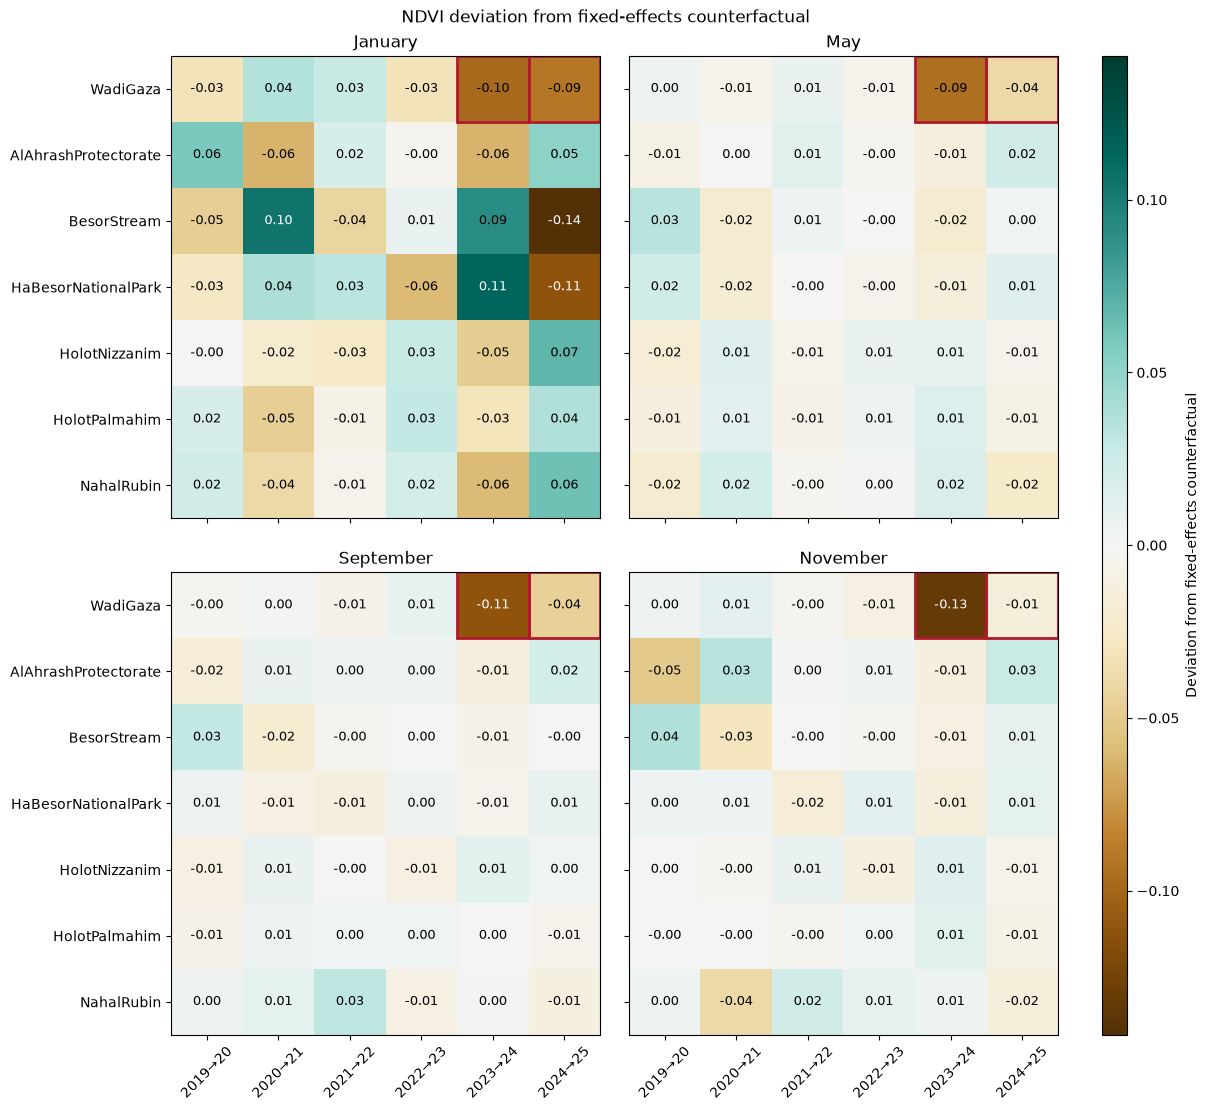

Period only model


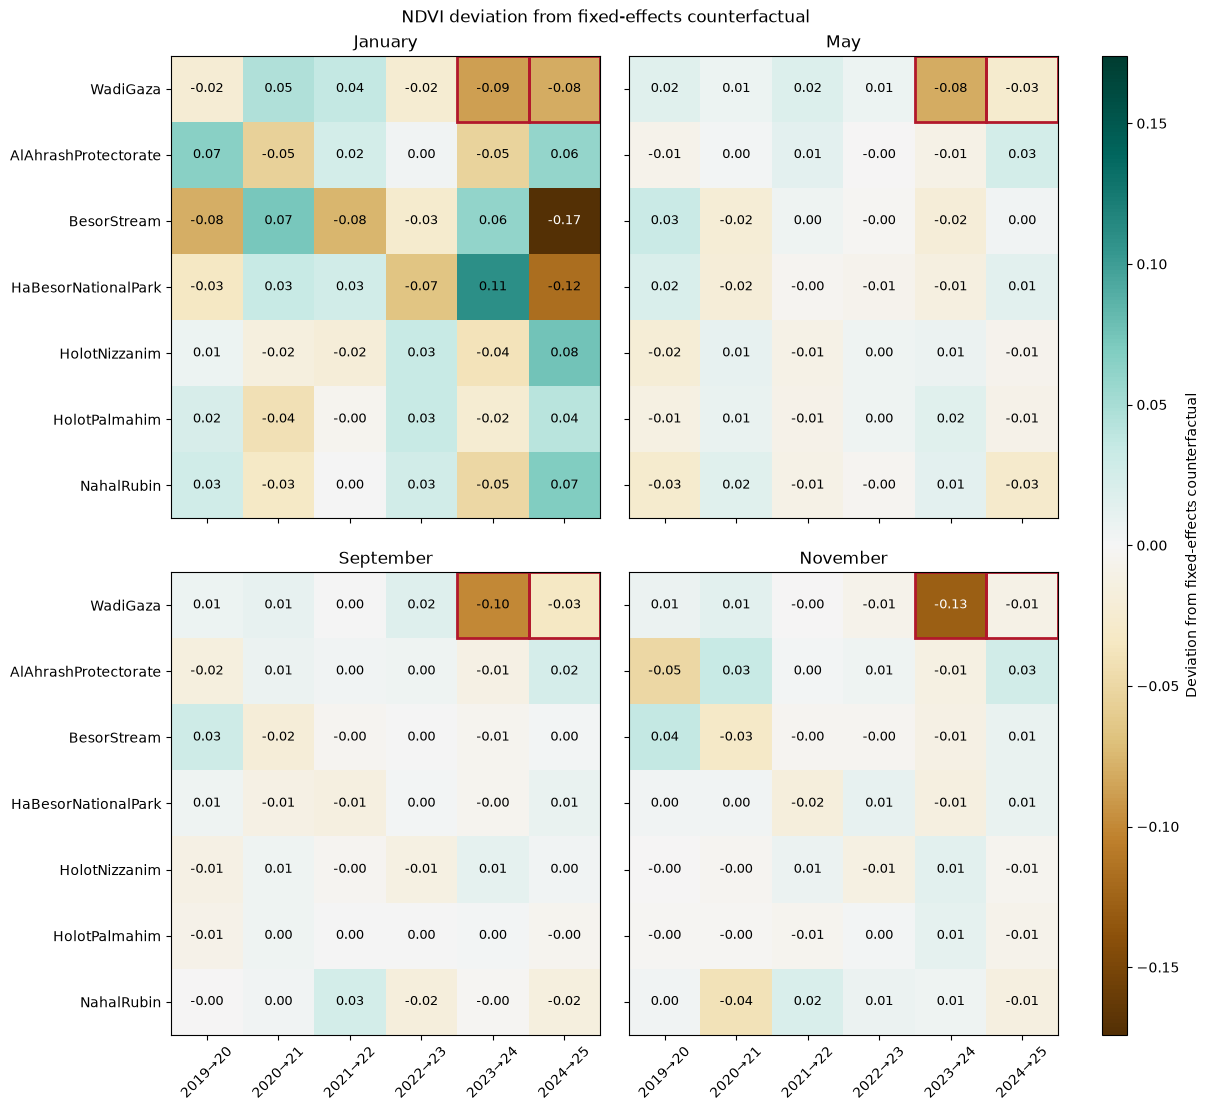

In [7]:
for index in CONFIG.indices:
    for model in MODELS:
        _, _, _, index_anomalies = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_anomaly_heatmap(
            index_anomalies,
            sites=site_order(index_anomalies["site"], CONFIG.affected_site),
        )
        fig.suptitle(f"{index} deviation from fixed-effects counterfactual")
        save_figure(fig, plot_dir / "anomaly_heatmap.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Observed vs counterfactual for the affected site

The dashed line is the model's counterfactual for the affected site (the
model's fixed effects with the event indicators zeroed); the solid line is
what was observed. The annotated gap at the first event pair equals the event
estimate β. Drawn once per model.


Site + period model


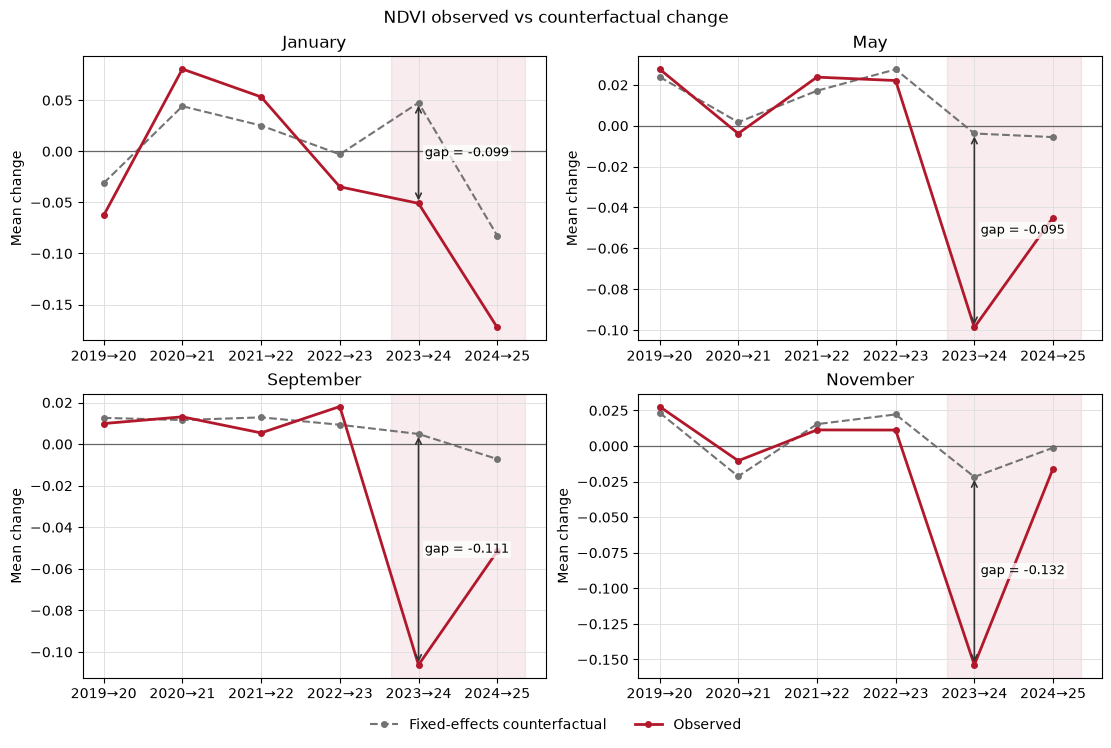

Period only model


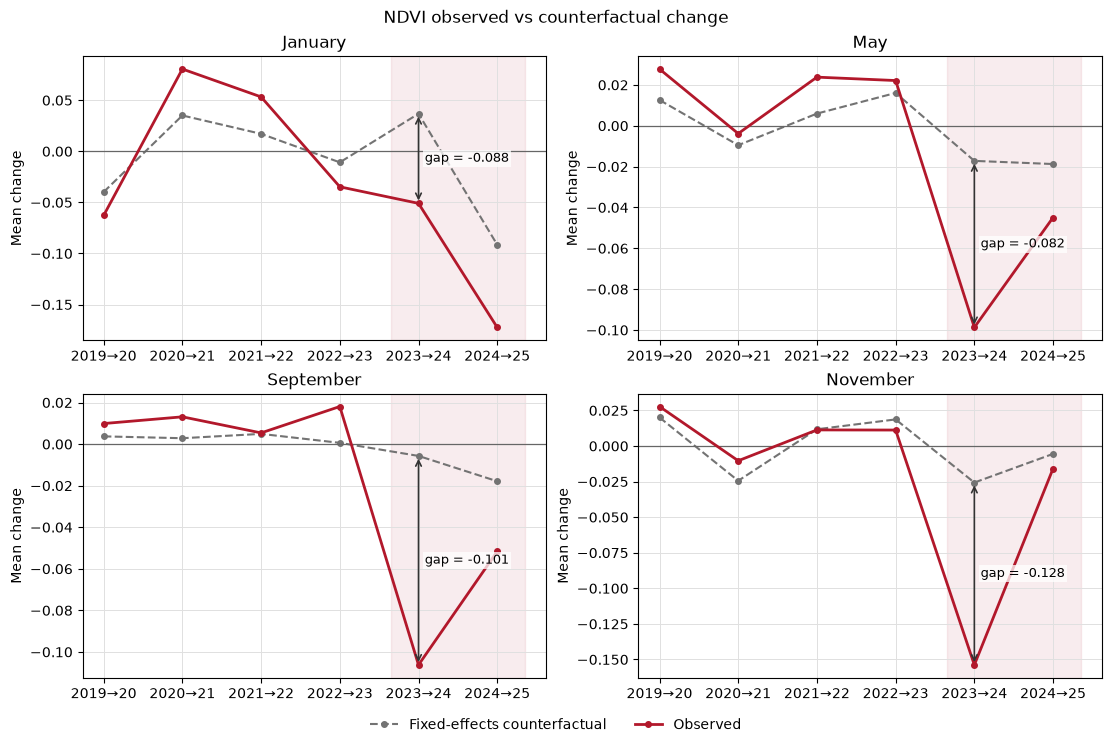

In [8]:
for index in CONFIG.indices:
    for model in MODELS:
        _, _, _, index_anomalies = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_observed_vs_counterfactual(
            index_anomalies, CONFIG.affected_site, CONFIG.event_pairs
        )
        fig.suptitle(f"{index} observed vs counterfactual change")
        save_figure(fig, plot_dir / "observed_vs_counterfactual.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Combined evidence per month

One panel per month stacking the lines of evidence on a shared axis, per
model: the event estimate with its 95% CI, the six placebo-in-space
estimates, and the 34 placebo-in-space-and-time estimates. Titles carry both
one-sided permutation p-values (floors 1/7 ≈ 0.143 and 1/35 ≈ 0.029).


Site + period model


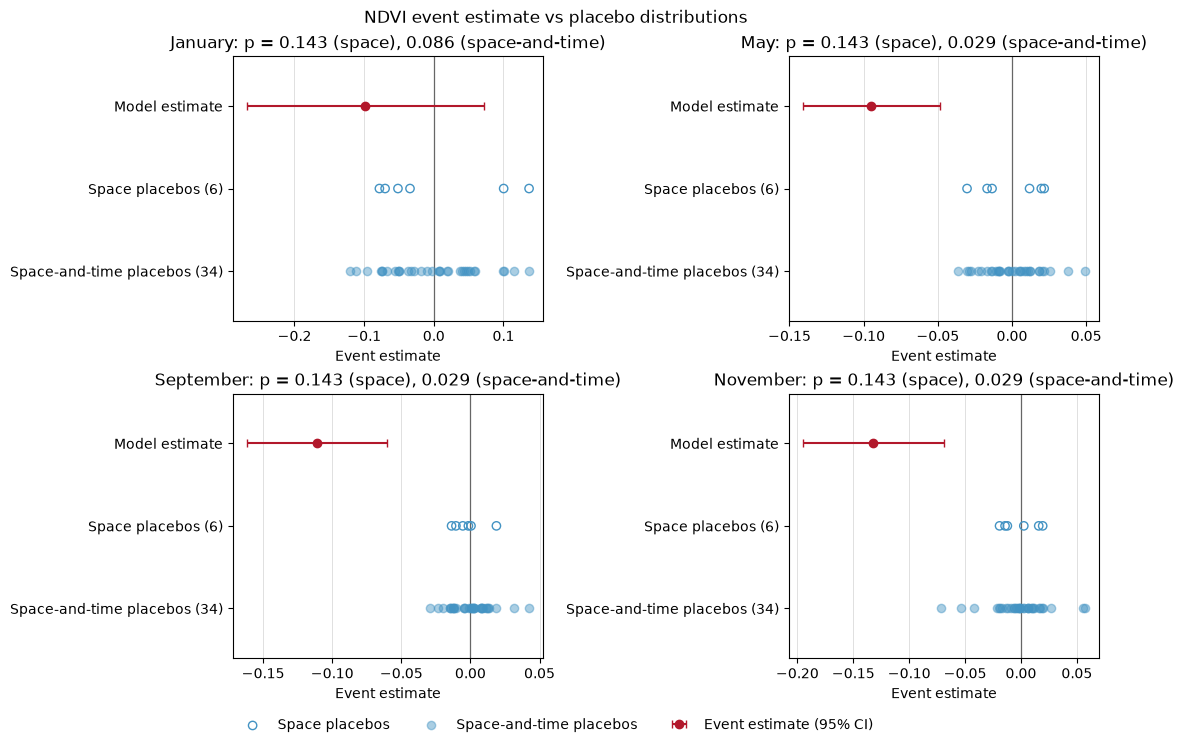

Period only model


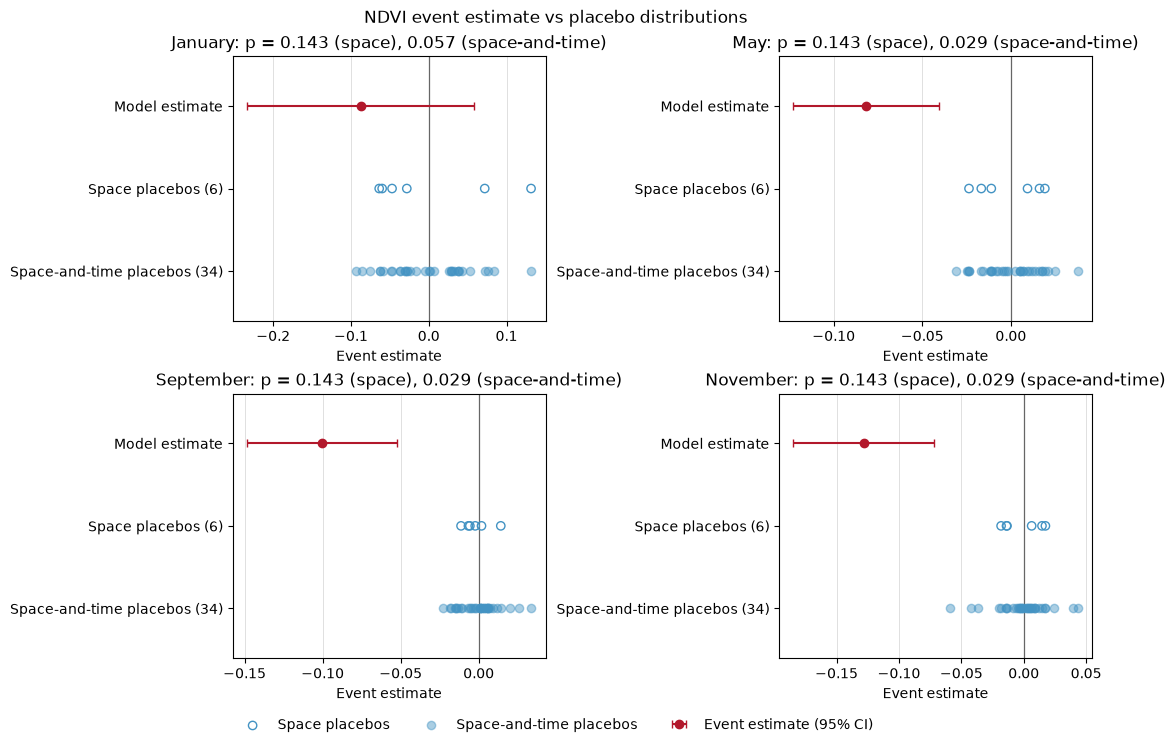

In [9]:
for index in CONFIG.indices:
    for model in MODELS:
        index_main, index_space, index_spacetime, _ = load_outputs(index, model)
        plot_dir = CONFIG.output_dir / index / "plots" / model
        fig, axes = plot_combined_evidence(index_main, index_space, index_spacetime)
        fig.suptitle(f"{index} event estimate vs placebo distributions")
        save_figure(fig, plot_dir / "combined_evidence.png")
        if index in SHOW_INDICES:
            print(f"{MODEL_LABELS[model]} model")
            plt.show()
        else:
            plt.close(fig)

## Combined evidence across indices

Transpose of the previous figure: one figure per study month and model with a
panel per index, so the combined placebo evidence can be compared across the
four indices for the same month. These figures span every index, so they are
saved under `outputs/index_comparison/plots/<model>/`.

Site + period model


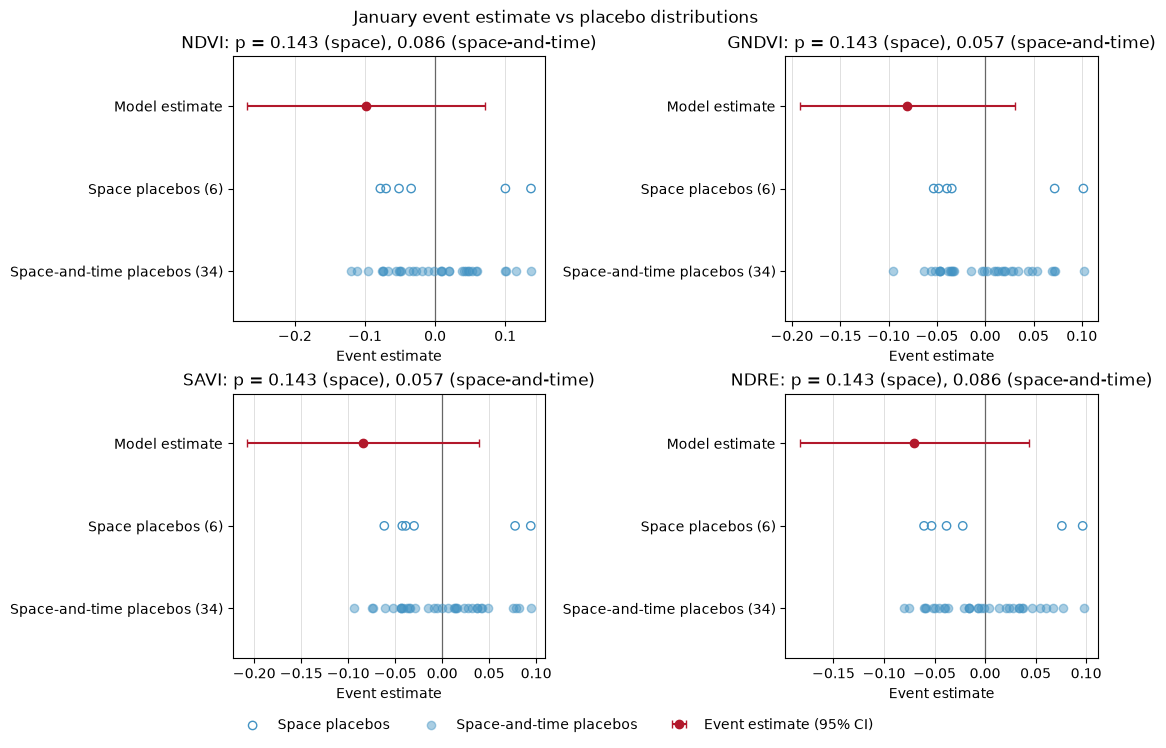

Site + period model


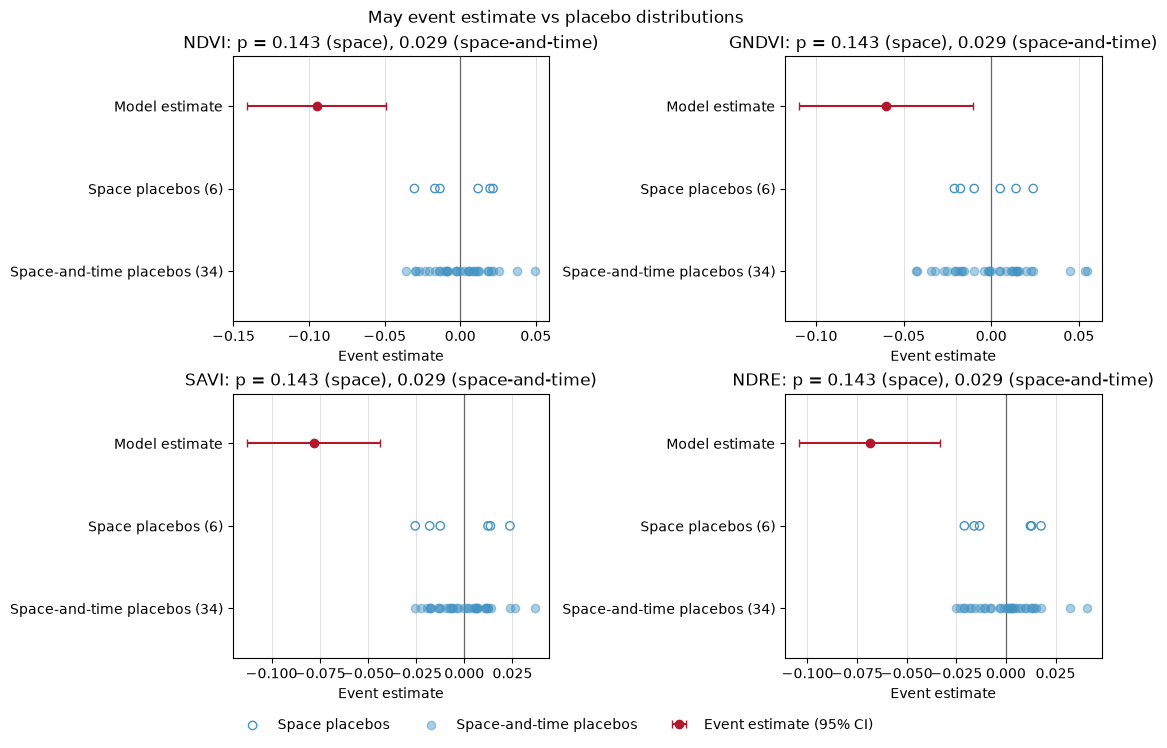

Site + period model


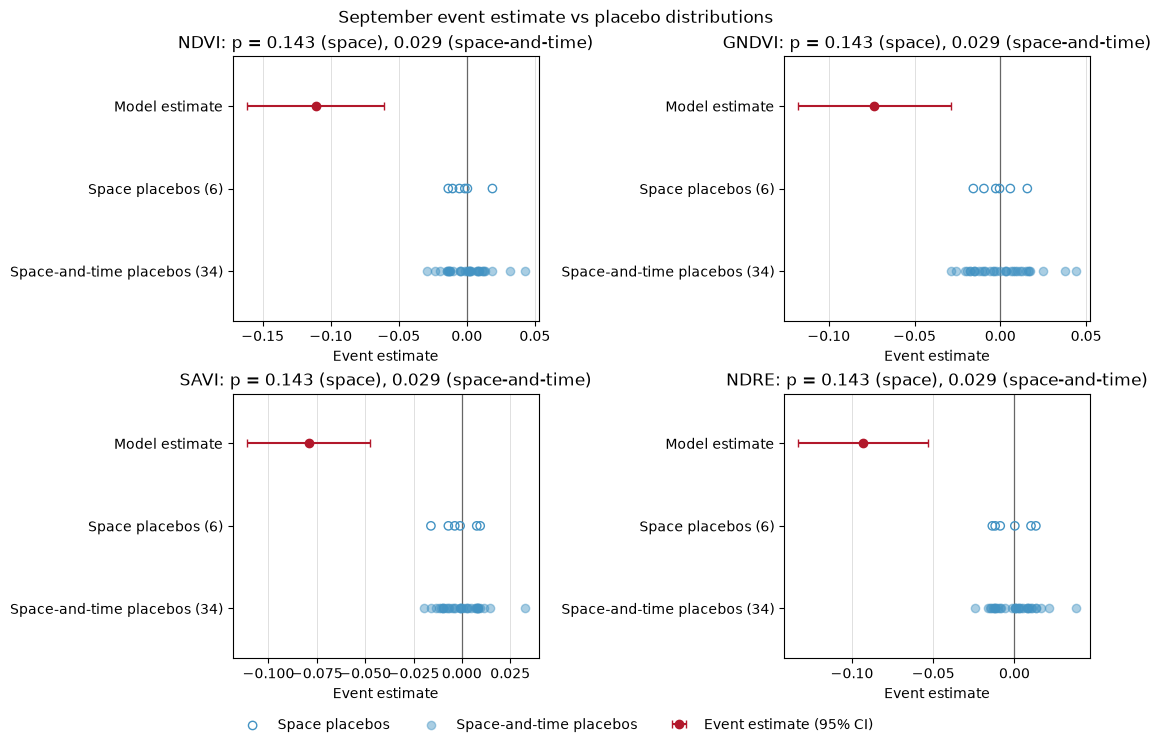

Site + period model


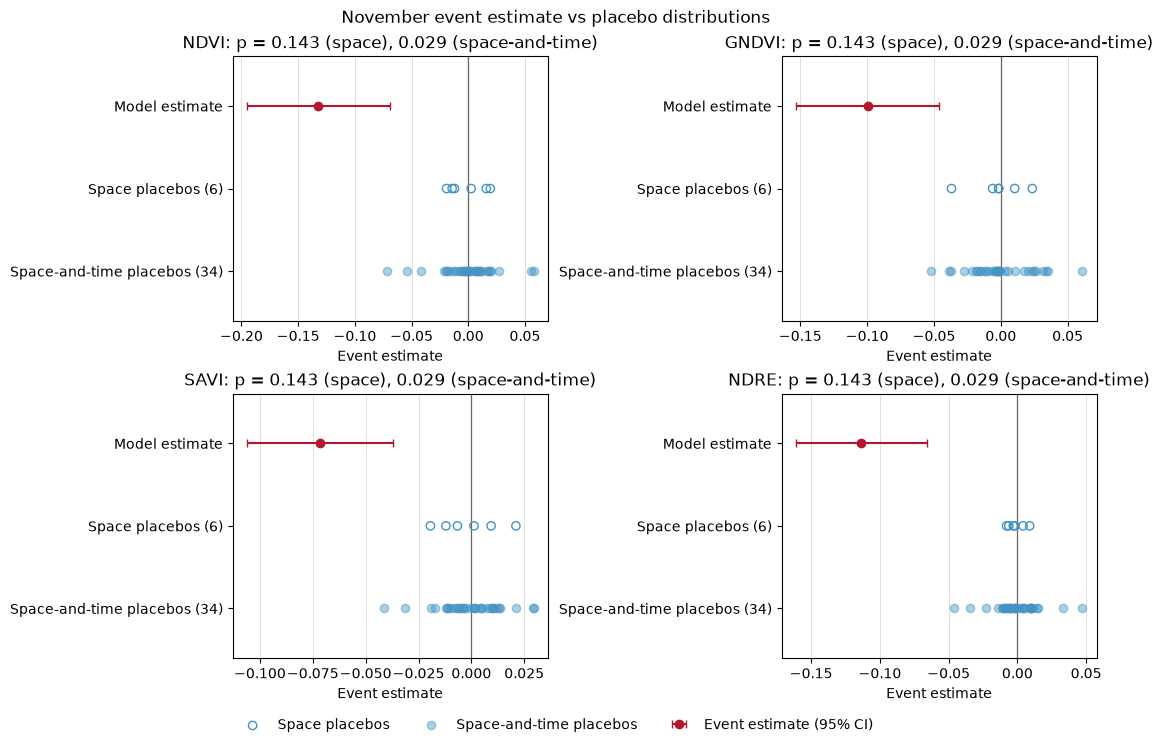

Period only model


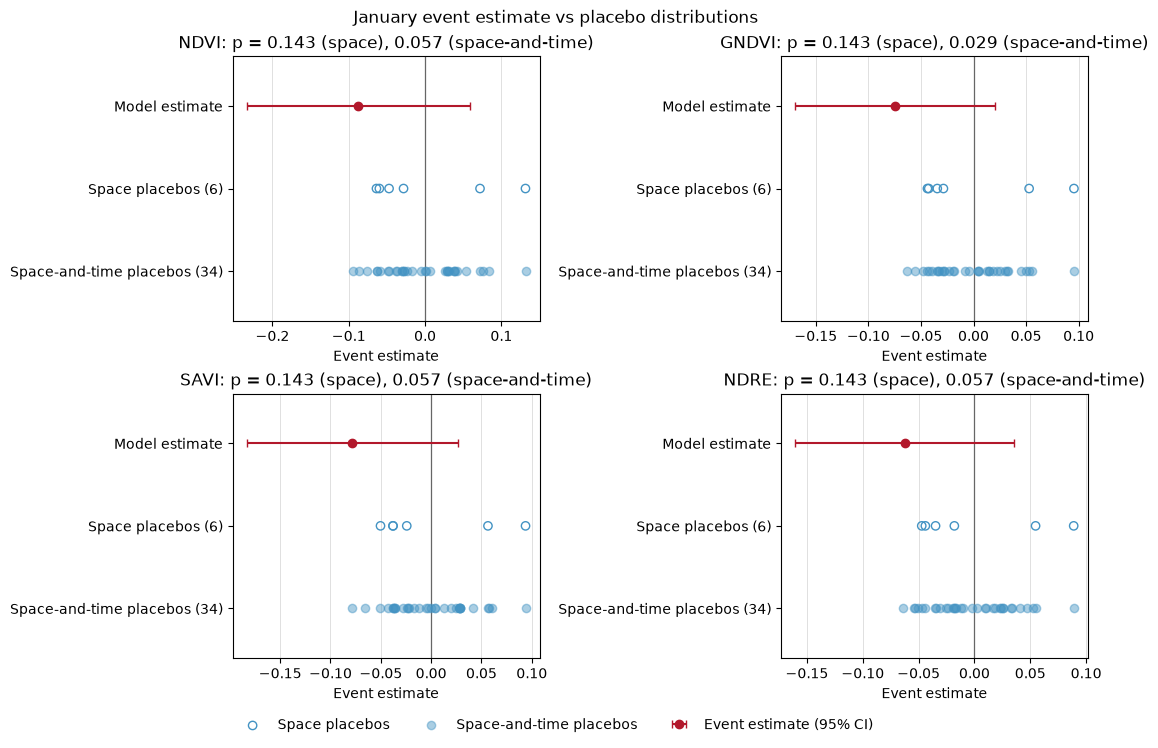

Period only model


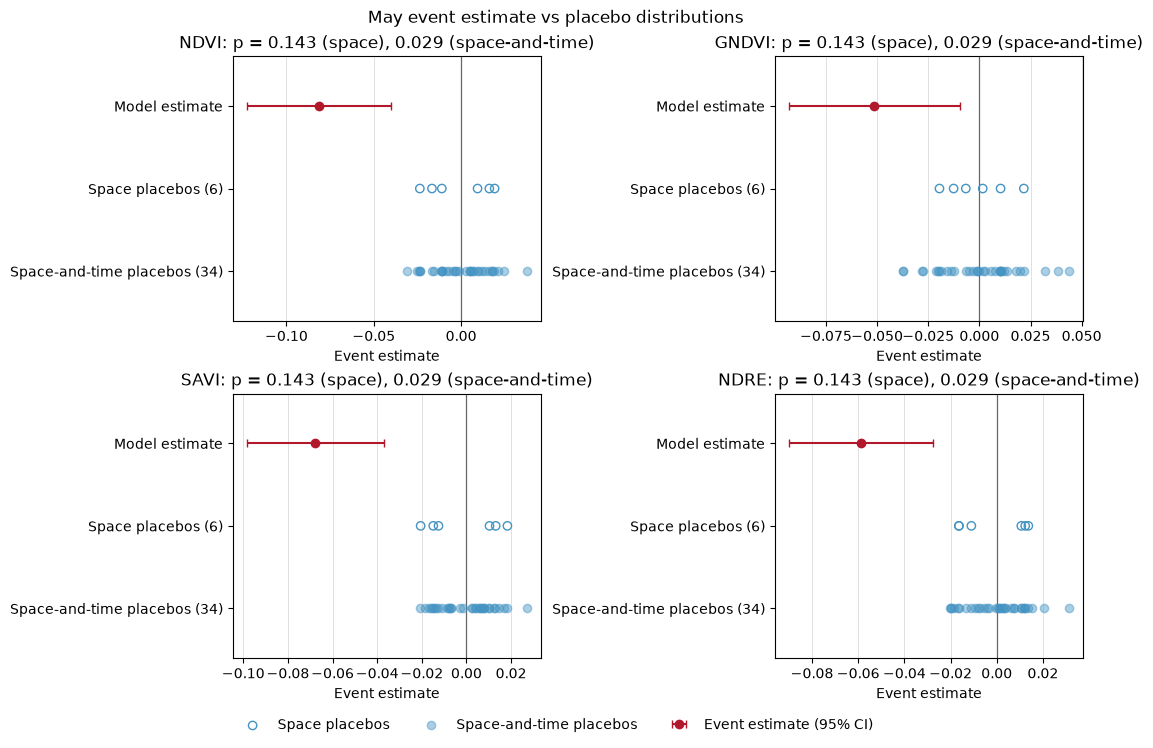

Period only model


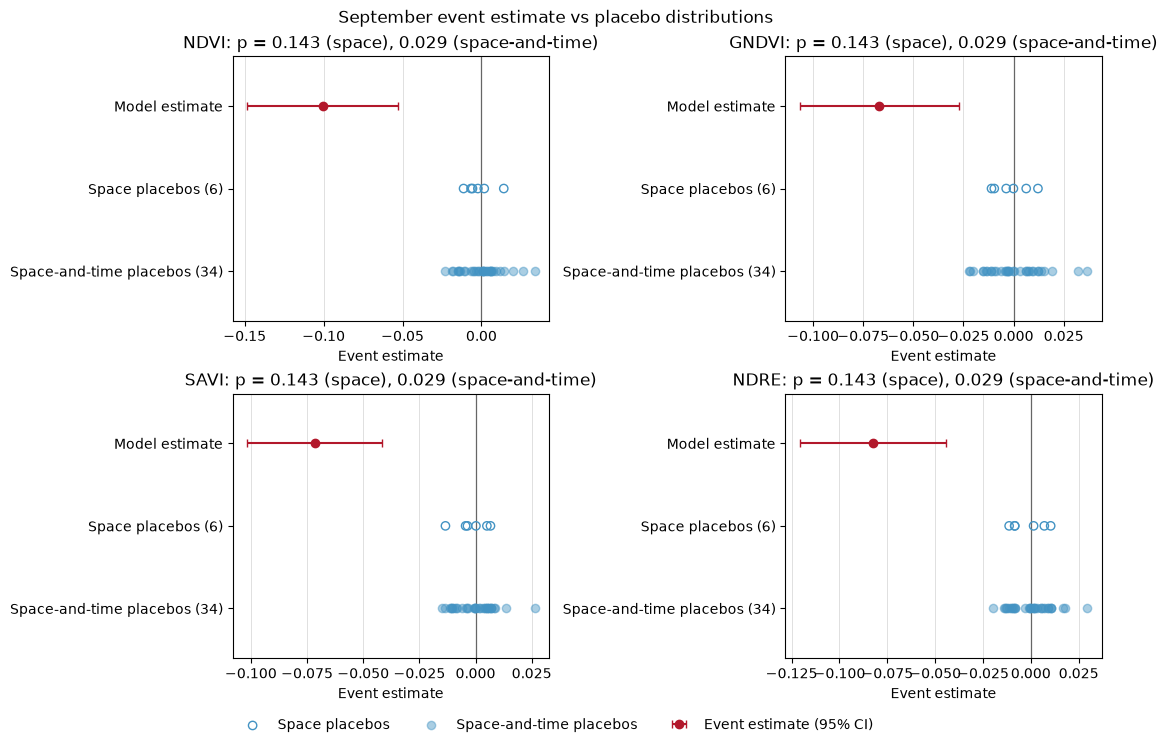

Period only model


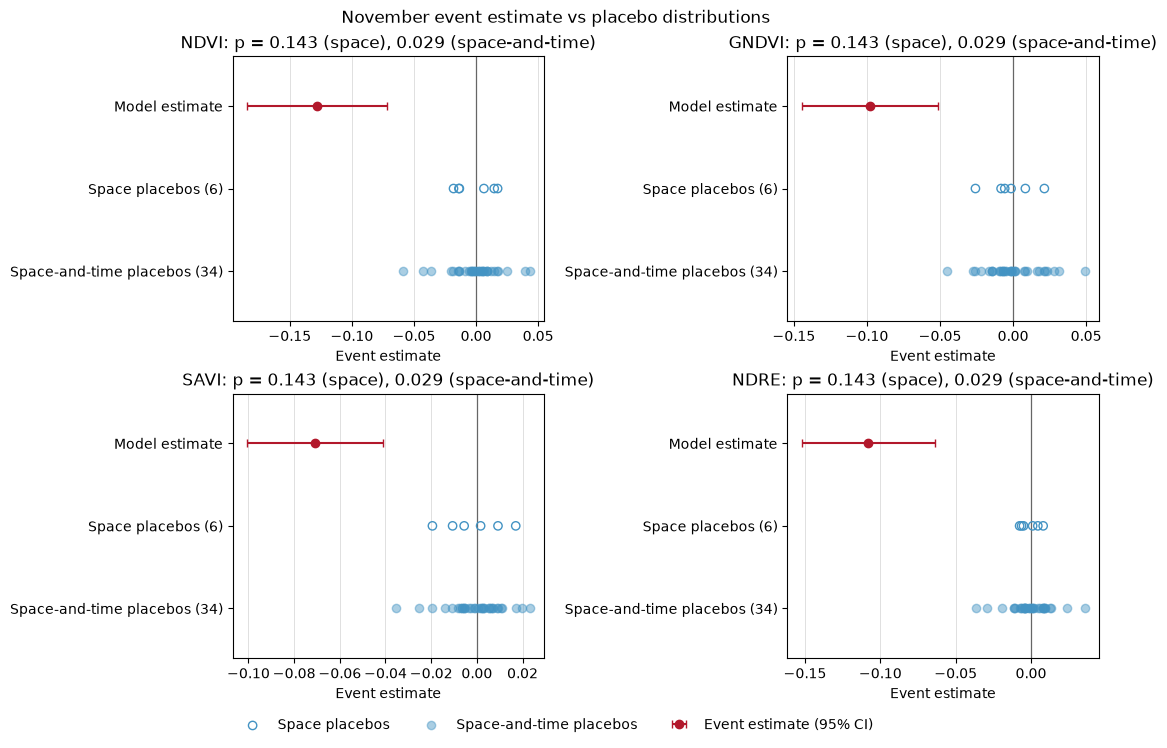

In [10]:
COMPARISON_PLOT_DIR = ROOT / "outputs" / "index_comparison" / "plots"

for model in MODELS:
    combined_inputs = {
        index: load_outputs(index, model)[:3] for index in CONFIG.indices
    }
    for month in CONFIG.months:
        fig, axes = plot_combined_evidence_by_index(combined_inputs, month)
        fig.suptitle(f"{month_name(month)} event estimate vs placebo distributions")
        save_figure(
            fig, COMPARISON_PLOT_DIR / model / f"combined_evidence_{int(month):02d}.png"
        )
        print(f"{MODEL_LABELS[model]} model")
        plt.show()

## Index-level trajectories in context

Annual mean index levels per site from the saved `index_ci` results, with the
affected site highlighted. The observation years following the event onset
are shaded. This is descriptive context in levels; the statistical model works
on changes, and the affected site's CI error bars are shown on the change
trajectories above.

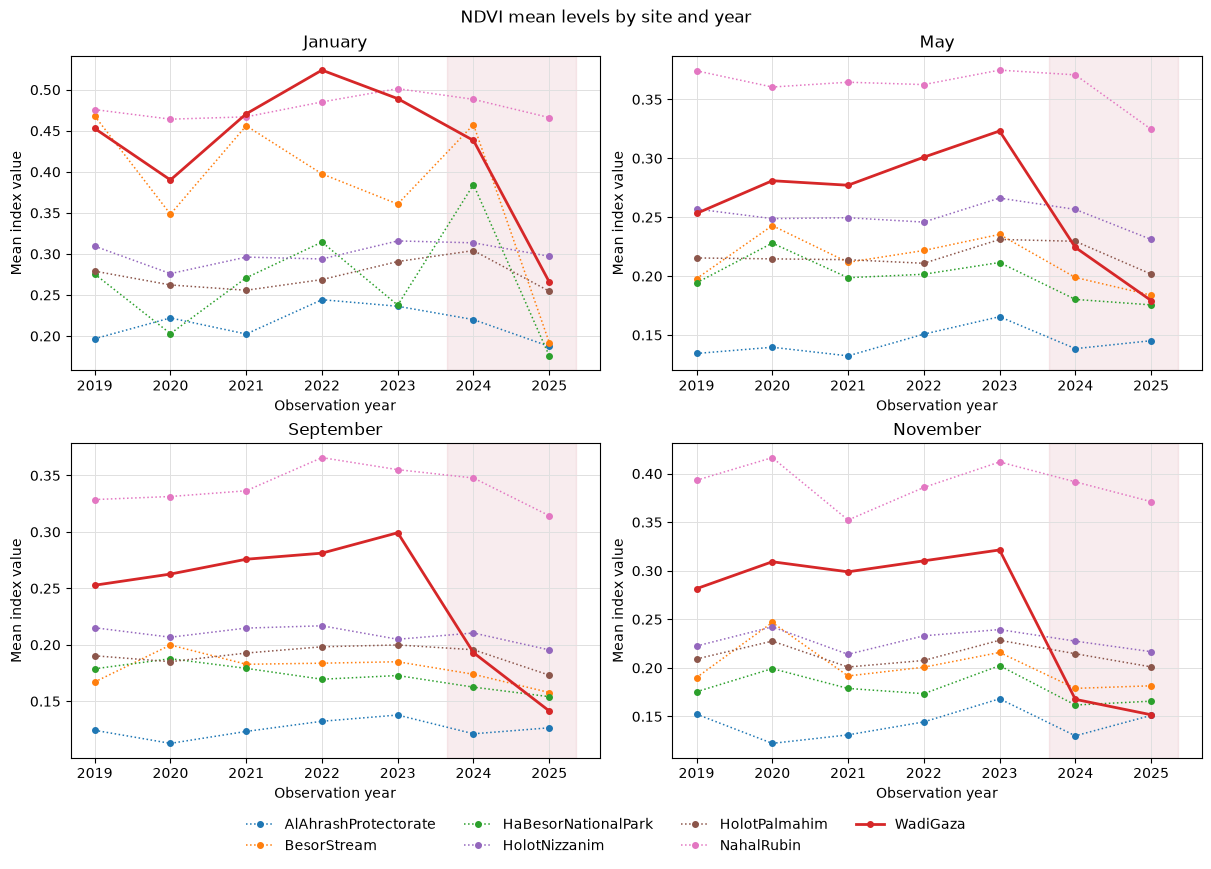

In [11]:
INDEX_CI_DIR = ROOT / "outputs" / "index_ci"
EVENT_YEARS = sorted({pair[1] for pair in CONFIG.event_pairs})

for index in CONFIG.indices:
    level_results = pd.read_csv(INDEX_CI_DIR / index / "results.csv")
    plot_dir = CONFIG.output_dir / index / "plots"
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, month in zip(axes.flat, CONFIG.months):
        plot_index_timeseries(
            level_results, group_by="study_area", filters={"month": month},
            show_ci_for=None, highlight=CONFIG.affected_site, ax=ax,
        )
        ax.axvspan(
            min(EVENT_YEARS) - 0.35, max(EVENT_YEARS) + 0.35,
            color="#b2182b", alpha=0.08, zorder=0,
        )
        ax.set_title(month_name(month))
    add_shared_legend(fig, axes)
    fig.suptitle(f"{index} mean levels by site and year")
    save_figure(fig, plot_dir / "level_trajectories.png")
    plt.show() if index in SHOW_INDICES else plt.close(fig)

## Index-level trajectories across indices

Transpose of the previous figure: one figure per study month with a panel per
index, so the four indices can be compared directly for the same month. These
figures span every index, so they are saved under `outputs/index_comparison/`
rather than any index-specific folder.

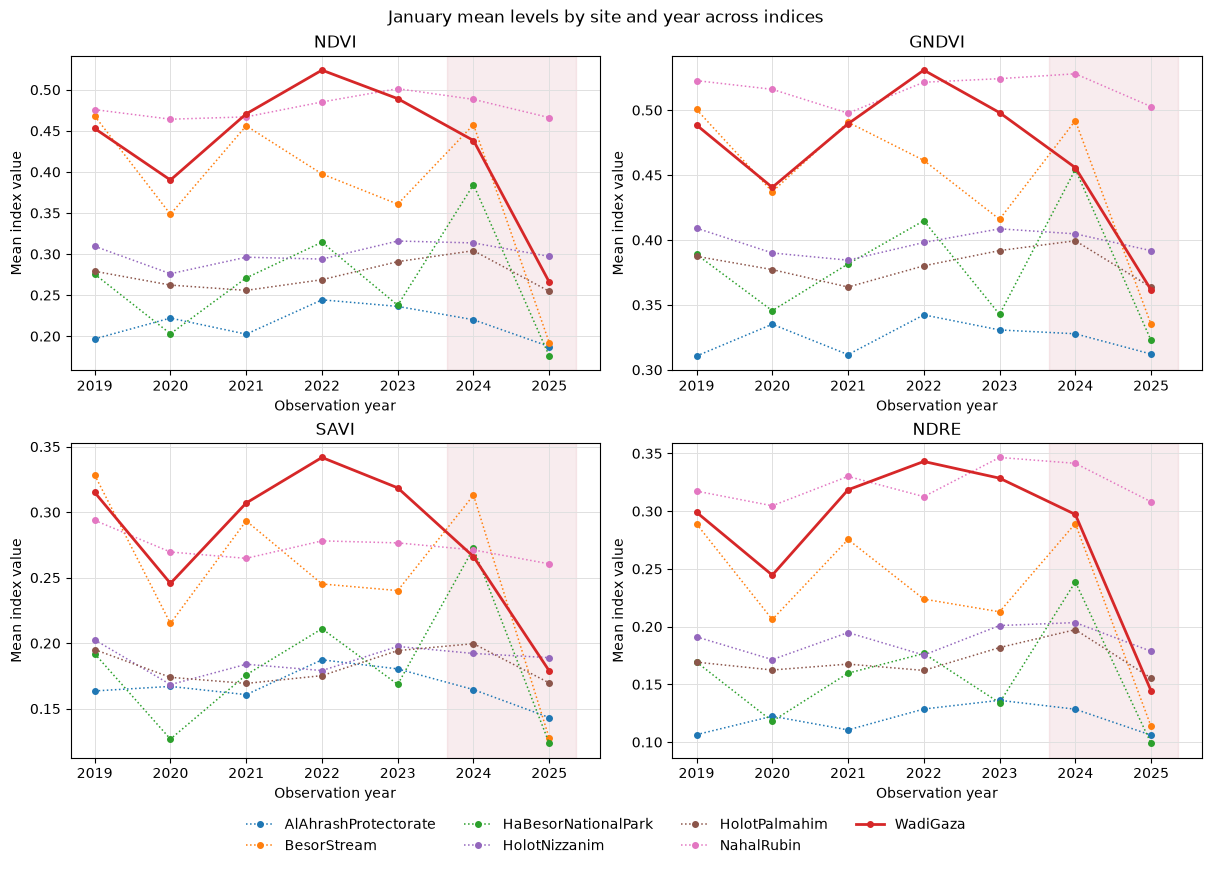

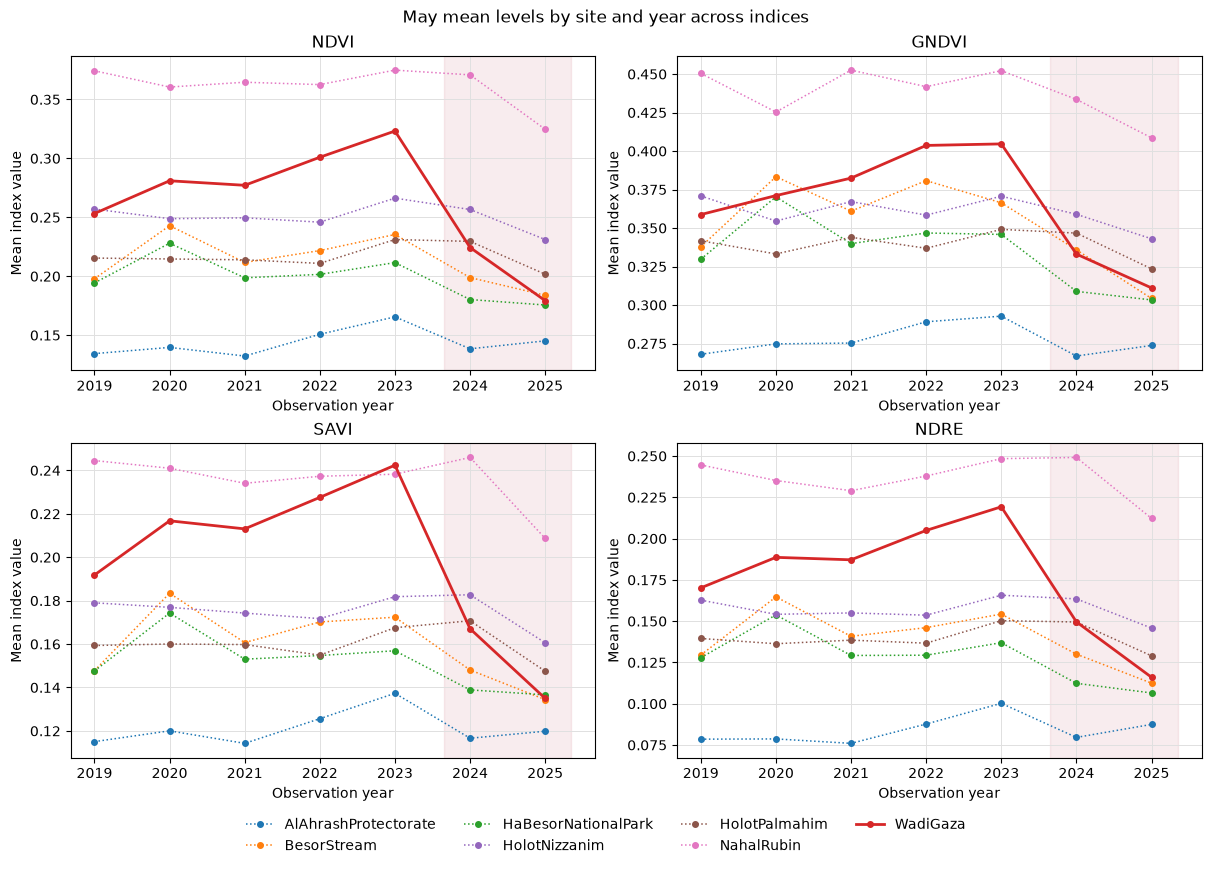

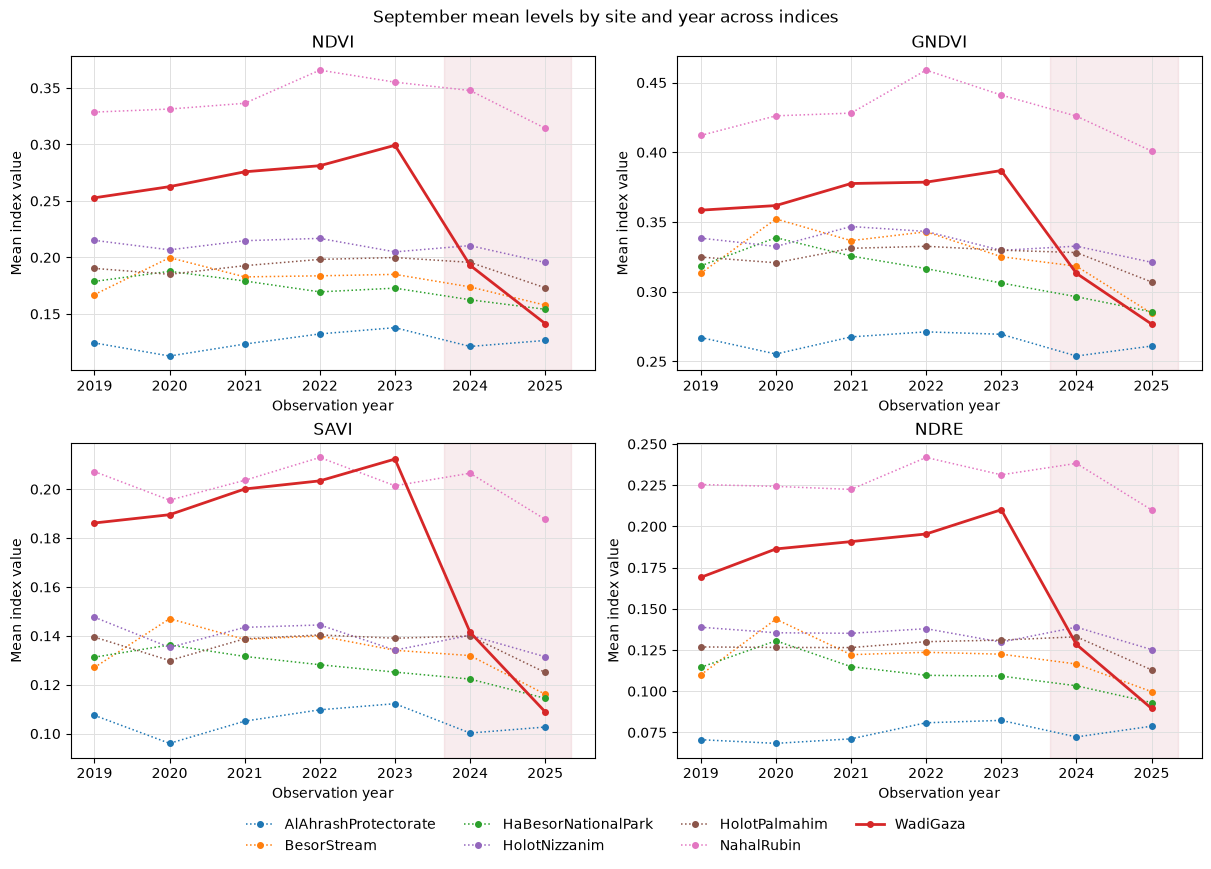

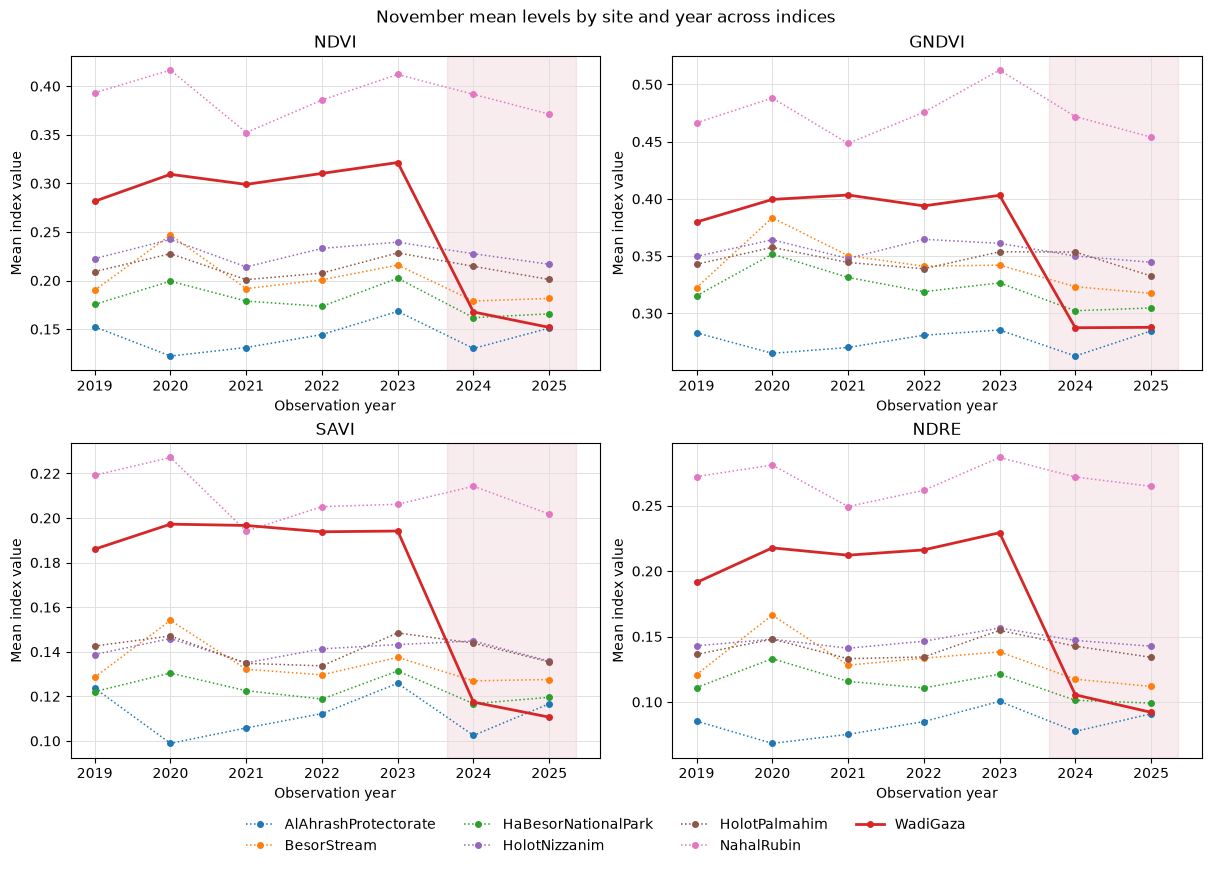

In [12]:
COMPARISON_PLOT_DIR = ROOT / "outputs" / "index_comparison" / "plots"
LEVEL_RESULTS = {
    index: pd.read_csv(INDEX_CI_DIR / index / "results.csv")
    for index in CONFIG.indices
}

for month in CONFIG.months:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    for ax, index in zip(axes.flat, CONFIG.indices):
        plot_index_timeseries(
            LEVEL_RESULTS[index], group_by="study_area", filters={"month": month},
            show_ci_for=None, highlight=CONFIG.affected_site, ax=ax,
        )
        ax.axvspan(
            min(EVENT_YEARS) - 0.35, max(EVENT_YEARS) + 0.35,
            color="#b2182b", alpha=0.08, zorder=0,
        )
        ax.set_title(index)
    add_shared_legend(fig, axes)
    fig.suptitle(f"{month_name(month)} mean levels by site and year across indices")
    save_figure(fig, COMPARISON_PLOT_DIR / f"level_trajectories_{int(month):02d}.png")
    plt.show()

## Summary tables

Per-model summary tables (deviation-coded site and year-pair effects with
joint Wald p-values, β and β′ with 95% CIs, and σ_u) are saved as
`did_summary_<model>.csv` next to each index's results and rendered in
`did_summary.md`.


In [13]:
from IPython.display import Markdown

Markdown((CONFIG.output_dir / PLOT_INDEX / "did_summary.md").read_text(encoding="utf-8"))

# Weighted fixed-effects model on index change

Primary specification: tau = 0.05, largest-SE fill, affected site WadiGaza. NDVI is the primary index; other indices are robustness checks. Supplementary months are flagged in their month label. Each model specification (site + period, and period only without site effects) is reported separately; site and year-pair effects use deviation (sum-to-zero) coding, so each is relative to the average site or year pair, with an asterisk where the 95% CI excludes zero.

Fits use statsmodels OLS/WLS with the leverage-adjusted Hedges (HE) method-of-moments variance estimator. Inverse estimated total-variance weights are treated as fixed, with covariance scale = 1, Student-t coefficient inference, and Wald F-tests.

## NDVI (primary)

### Site + period model

| Term | January (supplementary) | May | September | November |
| --- | --- | --- | --- | --- |
| AlAhrashProtectorate | 0.008 | 0.002 | 0.001 | -0.000 |
| BesorStream | -0.032 | -0.001 | -0.000 | -0.001 |
| HaBesorNationalPark | -0.005 | -0.002 | -0.001 | -0.001 |
| HolotNizzanim | 0.007 | -0.003 | -0.002 | -0.000 |
| HolotPalmahim | 0.005 | -0.001 | -0.001 | -0.001 |
| NahalRubin | 0.008 | -0.006 | -0.006 | -0.000 |
| WadiGaza | 0.009 | 0.011 | 0.009 | 0.003 |
| Joint p (sites) | 0.935 | 0.800 | 0.684 | 1.000 |
| 2019–20 | -0.031 | 0.014* | 0.005 | 0.021* |
| 2020–21 | 0.044 | -0.008 | 0.004 | -0.024* |
| 2021–22 | 0.025 | 0.007 | 0.006 | 0.013 |
| 2022–23 | -0.003 | 0.017* | 0.002 | 0.019* |
| 2023–24 | 0.048 | -0.014* | -0.002 | -0.025* |
| 2024–25 | -0.083* | -0.016* | -0.015* | -0.004 |
| Joint p (year pairs) | 0.009 | 0.001 | 0.048 | 0.000 |
| beta (2023–24) (95% CI) | -0.099 (-0.268, 0.071) | -0.095 (-0.141, -0.049)* | -0.111 (-0.162, -0.060)* | -0.132 (-0.195, -0.069)* |
| beta' (2024–25) (95% CI) | -0.090 (-0.255, 0.076) | -0.039 (-0.087, 0.008) | -0.044 (-0.095, 0.006) | -0.015 (-0.078, 0.048) |
| sigma_u | 0.063 | 0.015 | 0.010 | 0.018 |

### Period only model

| Term | January (supplementary) | May | September | November |
| --- | --- | --- | --- | --- |
| 2019–20 | -0.031 | 0.014* | 0.006 | 0.021* |
| 2020–21 | 0.044* | -0.008 | 0.005 | -0.024* |
| 2021–22 | 0.026 | 0.008 | 0.007 | 0.013* |
| 2022–23 | -0.002 | 0.018* | 0.003 | 0.020* |
| 2023–24 | 0.046* | -0.015* | -0.004 | -0.025* |
| 2024–25 | -0.083* | -0.017* | -0.016* | -0.005 |
| Joint p (year pairs) | 0.004 | 0.000 | 0.005 | 0.000 |
| beta (2023–24) (95% CI) | -0.088 (-0.234, 0.058) | -0.082 (-0.123, -0.040)* | -0.101 (-0.148, -0.053)* | -0.128 (-0.185, -0.072)* |
| beta' (2024–25) (95% CI) | -0.081 (-0.222, 0.060) | -0.026 (-0.069, 0.016) | -0.034 (-0.082, 0.014) | -0.010 (-0.067, 0.046) |
| sigma_u | 0.059 | 0.014 | 0.010 | 0.016 |

### Event estimates and placebo tests

| Model | Month | beta 2023–24 (95% CI) | p | beta' 2024–25 (95% CI) | sigma_u | Placebo-space p | Placebo-space-time p |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Site + period | January (supplementary) | -0.099 (-0.268, 0.071) | 0.24 | -0.090 (-0.255, 0.076) | 0.0629 | 0.143 | 0.086 |
| Site + period | May | -0.095 (-0.141, -0.049) | 0.00023 | -0.039 (-0.087, 0.008) | 0.0150 | 0.143 | 0.029 |
| Site + period | September | -0.111 (-0.162, -0.060) | 0.00011 | -0.044 (-0.095, 0.006) | 0.0104 | 0.143 | 0.029 |
| Site + period | November | -0.132 (-0.195, -0.069) | 0.00019 | -0.015 (-0.078, 0.048) | 0.0180 | 0.143 | 0.029 |
| Period only | January (supplementary) | -0.088 (-0.234, 0.058) | 0.23 | -0.081 (-0.222, 0.060) | 0.0592 | 0.143 | 0.057 |
| Period only | May | -0.082 (-0.123, -0.040) | 0.0003 | -0.026 (-0.069, 0.016) | 0.0143 | 0.143 | 0.029 |
| Period only | September | -0.101 (-0.148, -0.053) | 0.00015 | -0.034 (-0.082, 0.014) | 0.0096 | 0.143 | 0.029 |
| Period only | November | -0.128 (-0.185, -0.072) | 5.4e-05 | -0.010 (-0.067, 0.046) | 0.0161 | 0.143 | 0.029 |
